# 25 — Environmental EDA at native support

Moon and Earth development data only. Follow the adaptive design described below. Run All reads pinned existing inputs, preserves missingness and creates a new diagnostic run. The figures describe environmental context, not mission or equipment suitability.

## Setup and pinned inputs

In [7]:
import hashlib
import json
import sys
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Markdown, display
from pyproj import Transformer
from rasterio.crs import CRS
from rasterio.windows import Window

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.exploration.environment_analysis import diviner_cell_matrix
from notebooks.shared.inspection import check_input, file_hash, verify_run
from notebooks.shared.processing import MOON_CRS, MOON_GEOGRAPHIC

OUT = ROOT / 'data/processed/analysis' / ('environment-eda-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
expected = {}
evidence = {}


def pin(path):
    evidence[str(path.relative_to(ROOT))] = file_hash(path)
    return path


def register(stage, run_id):
    folder = ROOT / 'data/processed' / stage / run_id
    expected.update(verify_run(folder))
    pin(folder / 'provenance.json')
    return folder


def checked(path):
    temporary = {}
    check_input(path, expected, temporary)
    evidence[str(path.relative_to(ROOT))] = temporary[str(path.resolve())]
    return path


def savefig(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    fig.savefig(OUT / (name + '.pdf'), bbox_inches='tight')
    display(fig)
    plt.close(fig)


def short(region):
    return region.split('_', 2)[-1].replace('_', ' ')


climate_run = register('earth_climate', '20261028T014917410405Z_d7c8d5')
moon_run = register('lunar_terrain_environment', '20261028T022855014566Z_cffea7')
thermal_run = register('diviner_temperature', '20261028T022942126792Z_d44299')
views_run = register('lunar_terrain_views', '20261028T084443441751Z_1a794f')
osm_run = register('osm_support', '20261028T015656094003Z_ec31c5')
for name in ['notebooks/exploration/environment_analysis.py', 'notebooks/shared/inspection.py', 'notebooks/shared/processing.py',
             'data/reference/environment-readiness-20261028/native_layer_units.json',
             'data/reference/environment-eda-research-20261029/SOURCES.md']:
    pin(ROOT / name)
units = pd.read_json(ROOT / 'data/reference/environment-readiness-20261028/native_layer_units.json', encoding='utf-8-sig')
thermal_summary = pd.read_csv(checked(thermal_run / 'regional_bin_summary.csv'))
regions = sorted(thermal_summary.region.unique())
products = sorted(thermal_summary.source_product.unique())
presence = thermal_summary.pivot(index='region', columns='source_product', values='valid_temperature_rows').gt(0)
common_products = presence.columns[presence.all(axis=0)].tolist()
assert len(regions) == 7 and len(products) == 144 and len(common_products) == 17
pin(checked(thermal_run / 'interpretation.json'))
CONFIG = {'scope': 'Moon and Earth development only', 'earth_period': '2015-01 through 2024-12',
          'illumination': '60m solar/Earth visibility and PSR; 240m sky view, original region-center inclusion',
          'thermal_denominator': 'union of source centers observed in at least one product, including invalid rows',
          'joint_rule': 'containing native pixel at observed Diviner center; no interpolation or footprint completeness',
          'terrain_support': 'all five features finite at containing 30m cell, separately for both views',
          'common_products': common_products, 'physical_registration': 'unverified; technical coordinate consistency only'}


All data are existing development inputs. Missing environmental evidence remains **Unknown**.

## Earth climate variation and joint cell/month support

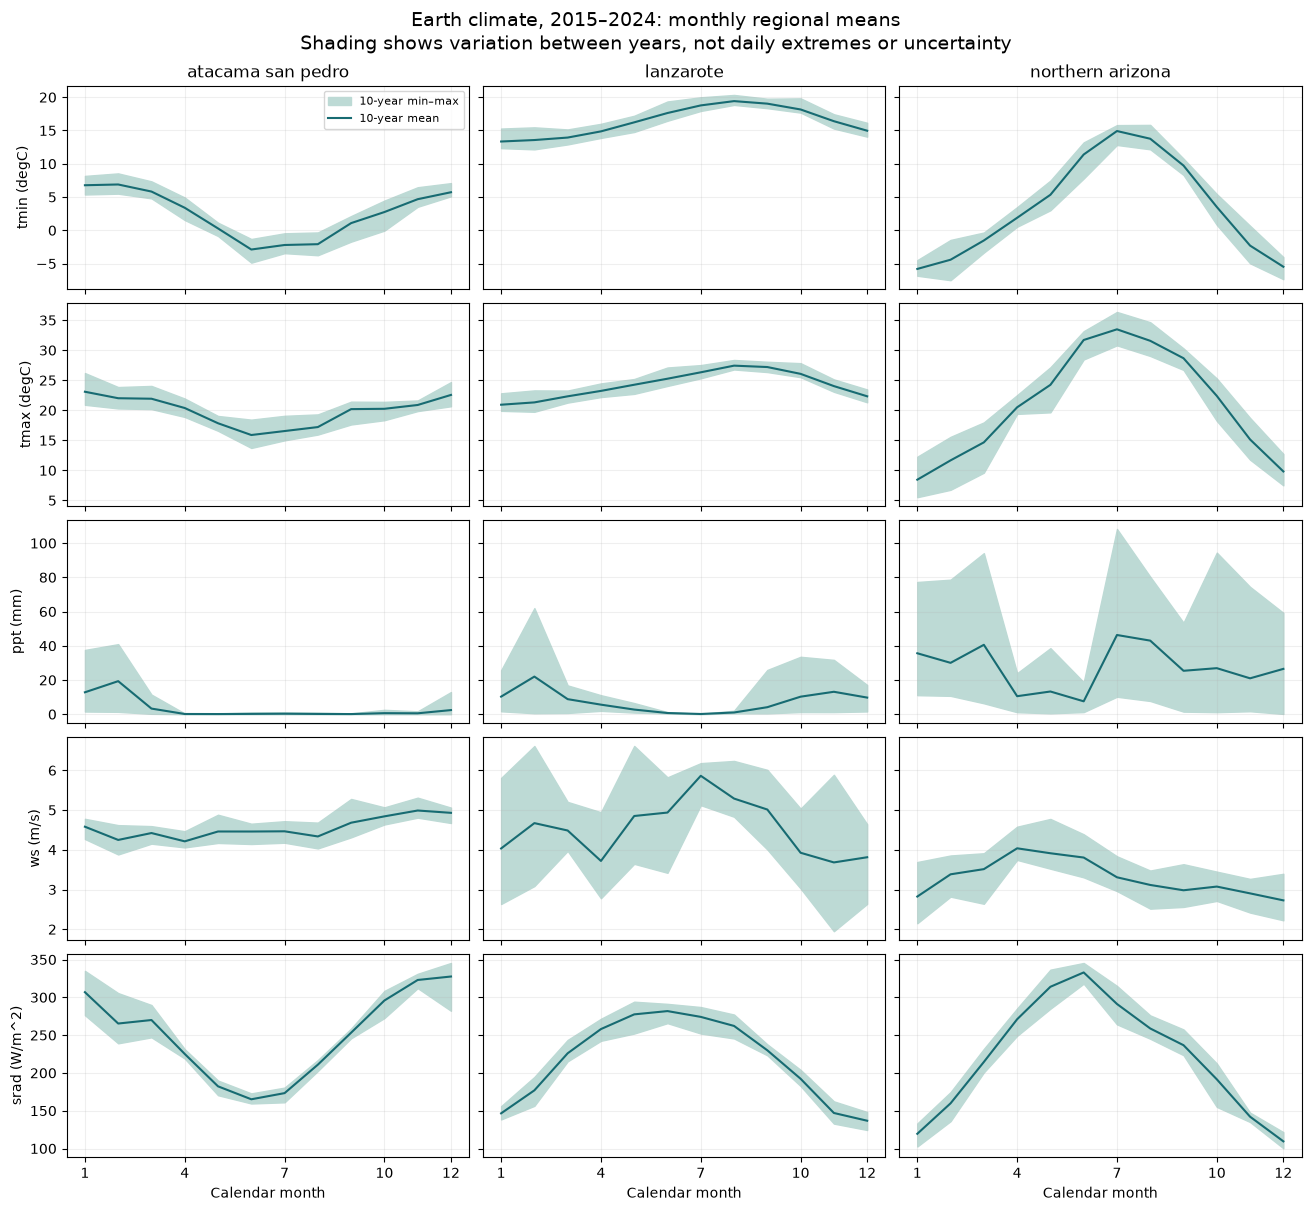

,area,selected_native_centers,complete_five_variable_120_month_centers,minimum_joint_month_centers,maximum_joint_month_centers,weighted_complete_fraction
0,atacama_san_pedro,285,285,285,285,1.000000
1,lanzarote,180,65,65,65,0.361115
2,northern_arizona,864,864,864,864,1.000000


In [8]:
climate = pd.read_csv(checked(climate_run / 'regional_monthly_summary.csv'), parse_dates=['date'])
areas = ['atacama_san_pedro', 'lanzarote', 'northern_arizona']
variables = ['tmin', 'tmax', 'ppt', 'ws', 'srad']
dates = pd.date_range('2015-01-01', '2024-12-01', freq='MS')
climate['month'] = climate.date.dt.month
climate['year'] = climate.date.dt.year
seasonal = climate.groupby(['area', 'variable', 'units', 'month']).spatial_weighted_mean.agg(['mean', 'min', 'max']).reset_index()
seasonal.to_csv(OUT / 'earth_monthly_climatology.csv', index=False)
climate_rows = []
spatial_rows = []
for area in areas:
    frames = [pd.read_csv(checked(p), parse_dates=['date']) for p in sorted((climate_run / 'earth' / area / 'native_monthly').glob('*.csv.gz'))]
    observations = pd.concat(frames, ignore_index=True)
    assert len(frames) == 50 and not observations.duplicated(['longitude', 'latitude', 'date', 'variable']).any()
    assert observations.valid.eq(np.isfinite(observations.value)).all()
    assert set(observations.variable) == set(variables) and set(observations.date) == set(dates)
    matrix = observations.pivot(index=['longitude', 'latitude'], columns=['date', 'variable'], values='value')
    matrix = matrix.reindex(columns=pd.MultiIndex.from_product([dates, variables], names=['date', 'variable']))
    joint = np.asarray(np.isfinite(matrix.to_numpy()).reshape(len(matrix), 120, 5).all(axis=2))
    weights = np.cos(np.deg2rad(matrix.index.get_level_values('latitude').to_numpy()))
    complete = joint.all(axis=1)
    climate_rows.append({'area': area, 'selected_native_centers': len(matrix),
                         'complete_five_variable_120_month_centers': int(complete.sum()),
                         'minimum_joint_month_centers': int(joint.sum(axis=0).min()),
                         'maximum_joint_month_centers': int(joint.sum(axis=0).max()),
                         'weighted_complete_fraction': float(weights[complete].sum() / weights.sum())})
    cell_table = matrix.index.to_frame(index=False)
    cell_table['joint_months_of_120'] = joint.sum(axis=1)
    cell_table.to_csv(OUT / f'climate_cells_{area}.csv', index=False)
    for _, group in observations.groupby(['date', 'variable']):
        date, variable = group.date.iloc[0], group.variable.iloc[0]
        values = group.value.to_numpy()
        valid = np.isfinite(values)
        weight = np.cos(np.deg2rad(group.latitude.to_numpy()))
        recomputed = np.average(values[valid], weights=weight[valid])
        original = climate.loc[(climate.area == area) & (climate.date == date) & (climate.variable == variable)].iloc[0]
        assert np.isclose(recomputed, original.spatial_weighted_mean, rtol=1e-12, atol=1e-10)
        assert np.isclose(weight[valid].sum() / weight.sum(), original.weighted_coverage)
        q10, median, q90 = np.quantile(values[valid], [.1, .5, .9])
        spatial_rows.append({'area': area, 'date': date, 'variable': variable, 'units': group.units.iloc[0],
                             'native_cell_q10': q10, 'native_cell_median': median, 'native_cell_q90': q90})
    del observations, matrix, frames
climate_coverage = pd.DataFrame(climate_rows)
climate_coverage.to_csv(OUT / 'climate_joint_coverage.csv', index=False)
pd.DataFrame(spatial_rows).to_csv(OUT / 'climate_spatial_quantiles.csv', index=False)
fig, axes = plt.subplots(5, 3, figsize=(13, 12), sharex=True, sharey='row', layout='constrained')
for j, area in enumerate(areas):
    for i, variable in enumerate(variables):
        part = seasonal.loc[(seasonal.area == area) & (seasonal.variable == variable)]
        ax = axes[i, j]
        ax.fill_between(part.month, part['min'], part['max'], color='#bddad5', label='10-year min–max')
        ax.plot(part.month, part['mean'], color='#176b72', label='10-year mean')
        ax.set_xticks([1, 4, 7, 10, 12])
        ax.grid(alpha=.2)
        if j == 0:
            ax.set_ylabel(f'{variable} ({part.units.iloc[0]})')
        if i == 0:
            ax.set_title(area.replace('_', ' '))
        if i == 4:
            ax.set_xlabel('Calendar month')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Earth climate, 2015–2024: monthly regional means\nShading shows variation between years, not daily extremes or uncertainty', fontsize=14)
savefig(fig, 'earth_climate_seasonality')
display(climate_coverage)

## Native lunar illumination and source/crop coordinate consistency

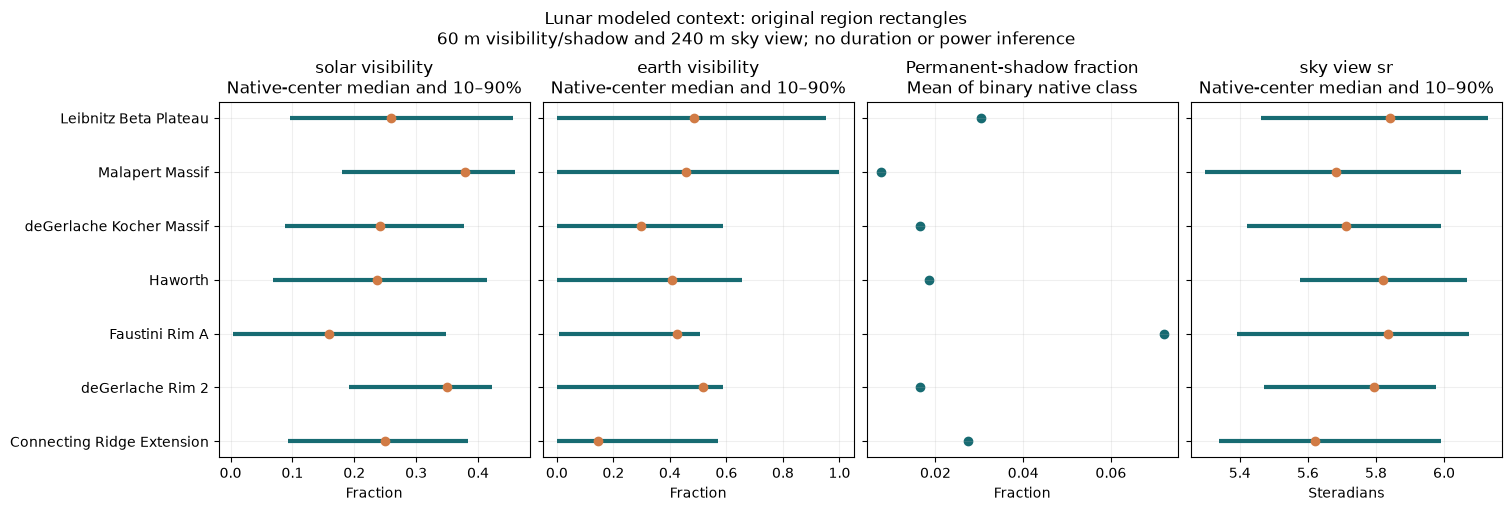

In [9]:
layer_files = {'solar_visibility': 'AVGVISIB_85S_060M_201608.TIF',
               'earth_visibility': 'AVGVISIB_85S_060M_201608_EARTH.TIF',
               'permanent_shadow': 'LPSR_85S_060M_201608.TIF',
               'sky_view_sr': 'SKYV_65S_240M.TIF'}
illumination_rows = []
grid_checks = []
region_bounds = {}
illumination_paths = {}
moon_provenance = json.loads((moon_run / 'provenance.json').read_text())
raw_hashes = {str((ROOT / path).resolve()): item['sha256'] for path, item in moon_provenance['inputs'].items()}
for region in regions:
    quality = json.loads(checked(moon_run / 'moon' / region / 'quality.json').read_text())
    west, south, east, north = quality['bounds_m']
    region_bounds[region] = (west, south, east, north)
    for layer, filename in layer_files.items():
        path = moon_run / 'moon' / region / 'native/illumination' / filename
        illumination_paths[region, layer] = path
        unit = units.loc[(units.region == region) & (units.file == filename)].iloc[0]
        assert unit.status == 'documented'
        meta = next(item for item in quality['native_layers'] if Path(item['source']).name == filename)
        source_path = Path(meta['source'])
        if str(source_path.relative_to(ROOT)) not in evidence:
            assert file_hash(source_path) == raw_hashes[str(source_path.resolve())]
            pin(source_path)
        with rasterio.open(checked(path)) as src, rasterio.open(source_path) as original:
            assert src.crs == original.crs == CRS.from_string(MOON_CRS)
            assert src.scales == (1.0,) and src.offsets == (0.0,)
            col_offset, row_offset = (~original.transform) * (src.transform.c, src.transform.f)
            assert np.allclose([col_offset, row_offset], np.round([col_offset, row_offset]), atol=1e-7)
            window = Window.from_slices((round(row_offset), round(row_offset) + src.height),
                                        (round(col_offset), round(col_offset) + src.width))
            assert original.window_transform(window).almost_equals(src.transform)
            raw = original.read(1, window=window, masked=True).astype('float32').filled(np.nan)
            decoded = raw * original.scales[0] + original.offsets[0]
            values = src.read(1, masked=True).astype('float32').filled(np.nan)
            np.testing.assert_allclose(values, decoded, rtol=1e-6, atol=1e-6, equal_nan=True)
            rows, cols = np.indices(src.shape)
            x = src.transform.c + (cols + .5) * src.transform.a
            y = src.transform.f + (rows + .5) * src.transform.e
            inside = (x >= west) & (x < east) & (y >= south) & (y < north)
            finite = values[inside & np.isfinite(values)]
            q10, median, q90 = np.quantile(finite, [.1, .5, .9])
            illumination_rows.append({'region': region, 'layer': layer, 'unit': unit.unit,
                                      'native_spacing_m': src.res[0], 'inside_centers': int(inside.sum()),
                                      'valid_centers': len(finite), 'mean': float(finite.mean()),
                                      'q10': q10, 'median': median, 'q90': q90,
                                      'minimum': float(finite.min()), 'maximum': float(finite.max())})
            grid_checks.append({'region': region, 'layer': layer, 'source_window_col': round(col_offset),
                                'source_window_row': round(row_offset), 'shape': list(src.shape),
                                'transform': list(src.transform), 'crs_equal': True,
                                'decoded_source_window_matches': True})
illumination = pd.DataFrame(illumination_rows)
illumination.to_csv(OUT / 'lunar_illumination_statistics.csv', index=False)
(OUT / 'source_crop_checks.json').write_text(json.dumps(grid_checks, indent=2), encoding='utf-8')
fig, axes = plt.subplots(1, 4, figsize=(15, 5), sharey=True, layout='constrained')
for ax, layer in zip(axes, layer_files, strict=True):
    part = illumination.loc[illumination.layer == layer].set_index('region').loc[regions]
    y = np.arange(len(regions))
    if layer == 'permanent_shadow':
        ax.scatter(part['mean'], y, color='#176b72')
        ax.set_title('Permanent-shadow fraction\nMean of binary native class')
    else:
        ax.hlines(y, part.q10, part.q90, color='#176b72', linewidth=3)
        ax.scatter(part['median'], y, color='#d17b45', zorder=3)
        ax.set_title(layer.replace('_', ' ') + '\nNative-center median and 10–90%')
    ax.set_xlabel('Steradians' if layer == 'sky_view_sr' else 'Fraction')
    ax.set_yticks(y, [short(r) for r in regions])
    ax.grid(alpha=.2)
axes[0].invert_yaxis()
fig.suptitle('Lunar modeled context: original region rectangles\n60 m visibility/shadow and 240 m sky view; no duration or power inference')
savefig(fig, 'lunar_illumination')

## Diviner cell-level phase coverage and contextual joint availability

Leibnitz Beta Plateau {'region': 'A3CLR22_10_Leibnitz_Beta_Plateau', 'observed_center_union': 4422, 'region_products_with_any_valid_cell': 103, 'centers_with_any_valid_temperature': 4422, 'centers_complete_144': 0, 'centers_complete_common_17': 84, 'common_17_complete_fraction': 0.018995929443690638, 'median_available_products': 92.0, 'minimum_available_products': 87, 'maximum_available_products': 101}
Malapert Massif {'region': 'A3CLR22_11_Malapert_Massif', 'observed_center_union': 7569, 'region_products_with_any_valid_cell': 113, 'centers_with_any_valid_temperature': 7569, 'centers_complete_144': 0, 'centers_complete_common_17': 6051, 'common_17_complete_fraction': 0.79944510503369, 'median_available_products': 102.0, 'minimum_available_products': 93, 'maximum_available_products': 107}
deGerlache Kocher Massif {'region': 'A3CLR22_12_deGerlache_Kocher_Massif', 'observed_center_union': 6972, 'region_products_with_any_valid_cell': 105, 'centers_with_any_valid_temperature': 6972, 'center

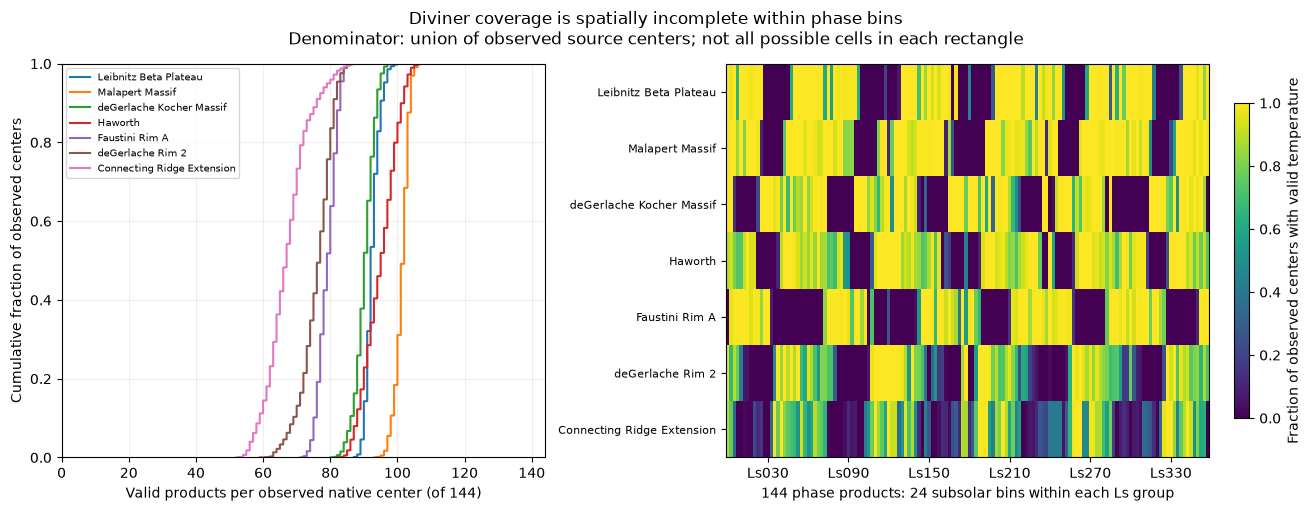

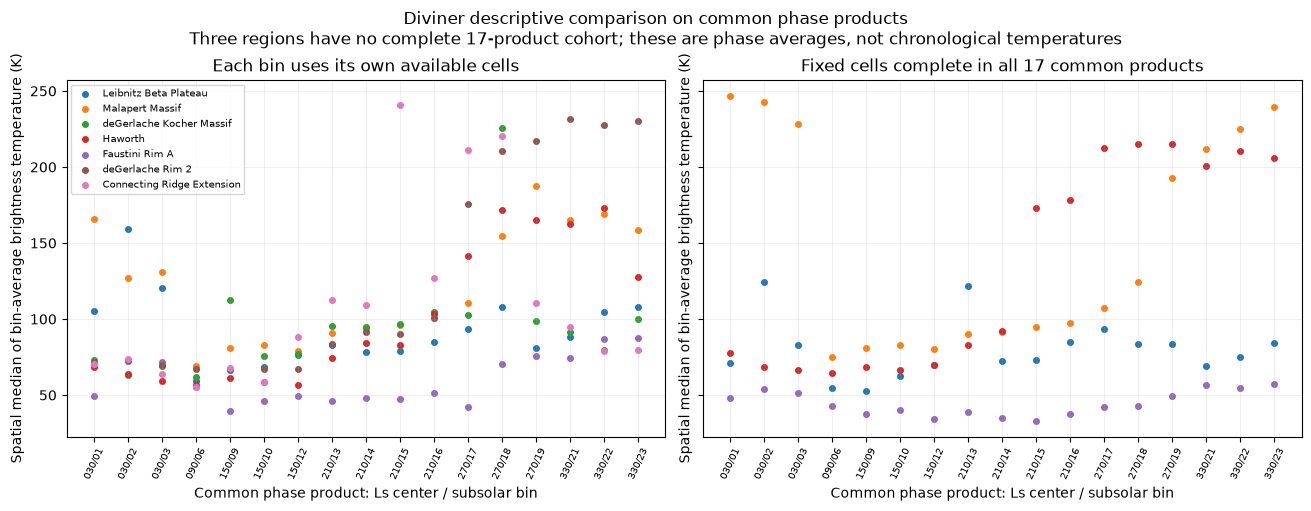

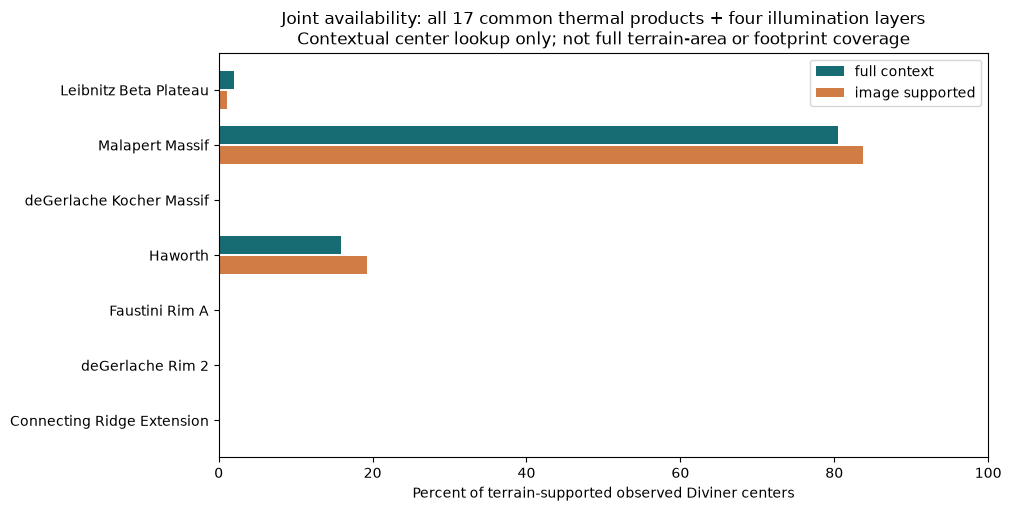

In [10]:
project = Transformer.from_crs(MOON_GEOGRAPHIC, MOON_CRS, always_xy=True)
channels = ['elevation_m', 'relative_elevation_m', 'slope_deg', 'laplacian_per_m', 'local_elevation_std_m']
thermal_rows = []
thermal_bin_rows = []
low_tail_rows = []
joint_rows = []
coverage_curves = {}


def sample_native(path, coordinates):
    with rasterio.open(checked(path)) as src:
        assert src.crs == CRS.from_string(MOON_CRS)
        samples = np.ma.vstack(list(src.sample(coordinates, masked=True))).astype(float).filled(np.nan)[:, 0]
    return samples


for region in regions:
    frames = [pd.read_csv(checked(p)) for p in sorted((thermal_run / 'moon' / region / 'native_240m').glob('*.csv.gz'))]
    assert len(frames) == 144
    observations = pd.concat([frame for frame in frames if not frame.empty], ignore_index=True)
    low_tail = observations.loc[observations.valid_temperature].nsmallest(10, 'tbol').copy()
    low_tail['region'] = region
    low_tail_rows.append(low_tail)
    matrix = diviner_cell_matrix(observations, products)
    centers = pd.DataFrame(observations[['clon', 'clat', 'x_m', 'y_m']]).drop_duplicates()
    assert not centers.duplicated(['clon', 'clat']).any()
    centers = centers.set_index(['clon', 'clat']).loc[matrix.index].reset_index()
    x, y = project.transform(centers.clon.to_numpy(), centers.clat.to_numpy())
    assert np.allclose(x, centers.x_m, atol=1e-6, rtol=0) and np.allclose(y, centers.y_m, atol=1e-6, rtol=0)
    west, south, east, north = region_bounds[region]
    assert ((x >= west) & (x < east) & (y >= south) & (y < north)).all()
    valid = matrix.notna()
    all_counts = np.asarray(valid.sum(axis=1).to_numpy())
    common_counts = np.asarray(valid[common_products].sum(axis=1).to_numpy())
    complete_common = common_counts == len(common_products)
    centers['available_products_of_144'] = all_counts
    centers['available_common_products_of_17'] = common_counts
    coords = list(zip(x, y, strict=True))
    for layer in layer_files:
        centers[layer] = sample_native(illumination_paths[region, layer], coords)
    illumination_available = np.isfinite(centers[list(layer_files)].to_numpy()).all(axis=1)
    centers['all_four_illumination_layers_available'] = illumination_available
    counts = {'region': region, 'observed_center_union': len(matrix),
              'region_products_with_any_valid_cell': int(np.asarray(valid.to_numpy()).any(axis=0).sum()),
              'centers_with_any_valid_temperature': int((all_counts > 0).sum()),
              'centers_complete_144': int((all_counts == 144).sum()),
              'centers_complete_common_17': int(complete_common.sum()),
              'common_17_complete_fraction': float(complete_common.mean()),
              'median_available_products': float(np.median(all_counts)),
              'minimum_available_products': int(all_counts.min()), 'maximum_available_products': int(all_counts.max())}
    thermal_rows.append(counts)
    coverage_curves[region] = all_counts
    for product in products:
        values = matrix[product].dropna().to_numpy()
        paired = matrix.loc[complete_common, product].dropna().to_numpy() if product in common_products else np.array([])
        thermal_bin_rows.append({'region': region, 'source_product': product, 'valid_centers': len(values),
                                 'observed_center_union': len(matrix),
                                 'fraction_of_observed_centers': len(values) / len(matrix),
                                 'spatial_median_bin_average_K': float(np.median(values)) if len(values) else np.nan,
                                 'spatial_q10_bin_average_K': float(np.quantile(values, .1)) if len(values) else np.nan,
                                 'spatial_q90_bin_average_K': float(np.quantile(values, .9)) if len(values) else np.nan,
                                 'complete_common_cohort_median_K': float(np.median(paired)) if len(paired) else np.nan})
    for view in ['full_context', 'image_supported']:
        support = np.ones(len(matrix), dtype=bool)
        for channel in channels:
            support &= np.isfinite(sample_native(views_run / 'moon' / region / view / (channel + '.tif'), coords))
        centers[view + '_complete_terrain_at_center'] = support
        joint = support & illumination_available & complete_common
        joint_rows.append({'region': region, 'terrain_view': view, 'observed_diviner_centers': len(matrix),
                           'terrain_complete_at_center': int(support.sum()),
                           'illumination_complete_at_center': int(illumination_available.sum()),
                           'common_17_thermal_complete': int(complete_common.sum()),
                           'joint_complete_at_center': int(joint.sum()),
                           'fraction_of_terrain_supported_centers': float(joint.sum() / support.sum()) if support.any() else np.nan})
    centers.to_csv(OUT / f'diviner_centers_{region}.csv.gz', index=False, compression={'method': 'gzip', 'mtime': 0})
    print(short(region), counts)
    del observations, frames, matrix
thermal = pd.DataFrame(thermal_rows)
thermal_bins = pd.DataFrame(thermal_bin_rows)
joint_table = pd.DataFrame(joint_rows)
thermal.to_csv(OUT / 'diviner_cell_coverage.csv', index=False)
thermal_bins.to_csv(OUT / 'diviner_bin_distributions.csv', index=False)
joint_table.to_csv(OUT / 'lunar_joint_availability.csv', index=False)
pd.concat(low_tail_rows, ignore_index=True).to_csv(OUT / 'diviner_low_tail_examples.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for region, counts in coverage_curves.items():
    ordered = np.sort(counts)
    axes[0].plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), label=short(region))
axes[0].set(xlabel='Valid products per observed native center (of 144)', ylabel='Cumulative fraction of observed centers', xlim=(0, 144), ylim=(0, 1))
axes[0].legend(fontsize=7)
axes[0].grid(alpha=.2)
fraction_matrix = thermal_bins.pivot(index='region', columns='source_product', values='fraction_of_observed_centers').loc[regions, products]
im = axes[1].imshow(fraction_matrix, aspect='auto', vmin=0, vmax=1, cmap='viridis')
axes[1].set_yticks(range(len(regions)), [short(r) for r in regions], fontsize=8)
axes[1].set_xticks([12 + 24*i for i in range(6)], [f'Ls{v:03d}' for v in [30, 90, 150, 210, 270, 330]])
axes[1].set_xlabel('144 phase products: 24 subsolar bins within each Ls group')
fig.colorbar(im, ax=axes[1], label='Fraction of observed centers with valid temperature', shrink=.8)
fig.suptitle('Diviner coverage is spatially incomplete within phase bins\nDenominator: union of observed source centers; not all possible cells in each rectangle')
savefig(fig, 'diviner_cell_coverage')
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, layout='constrained')
for region in regions:
    part = thermal_bins.loc[(thermal_bins.region == region) & thermal_bins.source_product.isin(common_products)].set_index('source_product').loc[common_products]
    axes[0].scatter(range(17), part.spatial_median_bin_average_K, s=16, label=short(region))
    axes[1].scatter(range(17), part.complete_common_cohort_median_K, s=16, label=short(region))
for ax, title in zip(axes, ['Each bin uses its own available cells', 'Fixed cells complete in all 17 common products'], strict=True):
    ax.set(title=title, xlabel='Common phase product: Ls center / subsolar bin', ylabel='Spatial median of bin-average brightness temperature (K)')
    ax.set_xticks(range(17), [p.split('_ls')[1].replace('_slon', '/').replace('_240', '') for p in common_products], rotation=65, fontsize=7)
    ax.grid(alpha=.2)
axes[0].legend(fontsize=7)
fig.suptitle('Diviner descriptive comparison on common phase products\nThree regions have no complete 17-product cohort; these are phase averages, not chronological temperatures')
savefig(fig, 'diviner_common_phase_temperature')
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for offset, view, color in [(-.18, 'full_context', '#176b72'), (.18, 'image_supported', '#d17b45')]:
    part = joint_table.loc[joint_table.terrain_view == view].set_index('region').loc[regions]
    ax.barh(np.arange(7) + offset, part.fraction_of_terrain_supported_centers * 100, height=.32, label=view.replace('_', ' '), color=color)
ax.set_yticks(np.arange(7), [short(r) for r in regions])
ax.invert_yaxis()
ax.set(xlabel='Percent of terrain-supported observed Diviner centers', xlim=(0, 100),
       title='Joint availability: all 17 common thermal products + four illumination layers\nContextual center lookup only; not full terrain-area or footprint coverage')
ax.legend()
savefig(fig, 'lunar_joint_availability')

## Region inventory, evidence boundaries, report and provenance

In [11]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/25_environment_native_support_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
inventory = []
for area in [*areas, 'death_valley', 'wadi_rum']:
    has_climate = area in areas
    osm_quality = osm_run / 'earth' / area / 'quality.json'
    row = {'body': 'Earth', 'region': area, 'terrain': 'available',
           'climate': 'native monthly 2015–2024' if has_climate else 'not acquired',
           'thermal_phase_products': 'not applicable', 'illumination': 'not applicable',
           'support_extract': 'available; completeness/access unknown' if osm_quality.exists() else 'not acquired',
           'equipment_suitability': 'Unknown: no mission/equipment specification'}
    if osm_quality.exists():
        quality = json.loads(checked(osm_quality).read_text())
        row.update({'osm_features': quality['feature_count'], 'osm_invalid_or_incomplete_areas': quality['diagnostics'].get('incomplete_or_invalid_area', 0)})
    inventory.append(row)
for region in regions:
    inventory.append({'body': 'Moon', 'region': region, 'terrain': 'full context + image supported',
                      'climate': 'not applicable', 'thermal_phase_products': '144 products with spatial/phase gaps',
                      'illumination': 'documented native modeled context', 'support_extract': 'not applicable',
                      'equipment_suitability': 'Unknown: missing mission limits and operational time evidence'})
pd.DataFrame(inventory).to_csv(OUT / 'region_evidence_inventory.csv', index=False)
capabilities = [
    ('Earth seasonal context', 'Descriptive', '3/5 sites; five monthly variables and common 2015–2024 period'),
    ('Earth weather extremes or operating windows', 'Unknown', 'Monthly means do not provide daily extremes or forecasts'),
    ('Earth access and emergency readiness', 'Unknown', 'OSM extracts are incomplete evidence and no access verification exists'),
    ('Lunar average visibility / shadow class', 'Descriptive', 'Native modeled fields; duration, station link and delivered energy are unsupported'),
    ('Lunar brightness-temperature phase context', 'Descriptive with quality hold', 'Partial source-cell records; no per-row uncertainty or retrieval-quality flags'),
    ('Lunar mission-duration thermal/power constraints', 'Unknown', 'Phase composites and modeled averages are not a synchronized operating time series'),
    ('Equipment compatibility / combined suitability', 'Unknown', 'Mission/equipment specifications and justified limits are absent'),
]
pd.DataFrame(capabilities, columns=pd.Index(['question', 'status', 'reason'])).to_csv(OUT / 'constraint_evidence_status.csv', index=False)
lines = [
    *report_notes['narrative-3d4f850e-1'].split('\n'),
]
for row in climate_rows:
    lines.append(f"- {row['area']}: {row['complete_five_variable_120_month_centers']}/{row['selected_native_centers']} selected native centers have all five variables for all 120 months ({100*row['weighted_complete_fraction']:.2f}% cosine-latitude weighted support).")
lines += [
    *report_notes['narrative-3d4f850e-2'].split('\n'),
]
for row in thermal_rows:
    lines.append(f"- {short(row['region'])}: {row['region_products_with_any_valid_cell']}/144 products have data somewhere; {row['centers_complete_common_17']}/{row['observed_center_union']} observed centers have all 17 common products ({100*row['common_17_complete_fraction']:.1f}%). {row['centers_complete_144']} centers have all 144 products.")
delta = thermal_bins.complete_common_cohort_median_K - thermal_bins.spatial_median_bin_average_K
largest_change = thermal_bins.loc[delta.abs().idxmax()]
lines += [
    *report_notes['narrative-3d4f850e-3'].split('\n'),
    f'The largest complete-cohort versus available-cell median difference is {delta.loc[delta.abs().idxmax()]:.1f} K in {short(largest_change.region)}, {largest_change.source_product}. This changes the represented spatial sample, not the measured temperature of a fixed cell. The separate low-tail table preserves ten lowest source rows per region with coordinates and product IDs; no retrieval-quality cutoff was applied.',
    *report_notes['narrative-3d4f850e-4'].split('\n'),
    'See [design](../../../../notebooks/exploration/25_environment_native_support_eda.ipynb), [primary-source interpretation](../../../reference/environment-eda-research-20261029/SOURCES.md), [unit policy](../../../reference/environment-readiness-20261028/REPORT.md) and the CSV/JSON outputs in this directory. The co-availability table describes containing native pixels at observed Diviner centers. It does not claim full 240 m footprints, all terrain patches, synchronized conditions, continuous sunlight, communication reliability, battery duration or equipment survivability.',
    *report_notes['narrative-3d4f850e-5'].split('\n'),
]
report = '\n'.join(lines) + '\n'
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
record = {'status': 'publishing', 'notebook': 'exploration/25_environment_native_support_eda.ipynb',
          'configuration': CONFIG, 'inputs': evidence,
          'outputs': {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file()},
          'software': {'python': sys.version, 'numpy': np.__version__, 'pandas': pd.__version__, 'rasterio': rasterio.__version__}}
executing_notebook = nbformat.read(ROOT / 'notebooks' / record['notebook'], as_version=4)
record['notebook_code_sha256'] = hashlib.sha256(json.dumps(
    [cell.source for cell in executing_notebook.cells if cell.cell_type == 'code'], ensure_ascii=False).encode()).hexdigest()
(OUT / 'provenance.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
display(Markdown(report))
print('Completed:', OUT)

# Environmental EDA: native support and joint availability

Scope: five Earth development sites and seven lunar development regions. Mars and reserves are excluded.

## Earth climate

Only the original three Earth sites have climate and OSM inputs. Death Valley and Wadi Rum are environmental acquisition gaps, not failed constraints. The 1,800 monthly regional means were independently recomputed from native decoded observations and agree with preprocessing.

- atacama_san_pedro: 285/285 selected native centers have all five variables for all 120 months (100.00% cosine-latitude weighted support).
- lanzarote: 65/180 selected native centers have all five variables for all 120 months (36.11% cosine-latitude weighted support).
- northern_arizona: 864/864 selected native centers have all five variables for all 120 months (100.00% cosine-latitude weighted support).

These are native selected-center denominators, not exact land-area completeness. Lanzarote retains ocean/coastal holes. Monthly climatology figures show regional means and between-year ranges; native-cell spatial quantiles are saved separately. tmin/tmax describe monthly average minimum/maximum temperatures, not observed monthly extremes.

The monthly tmin climatology spans -5.80 to 14.92 degC in Arizona, -2.88 to 6.89 degC in Atacama and 13.35 to 19.41 degC in Lanzarote. Arizona has the widest seasonal temperature range of these three boxes. Atacama radiation is lowest around June while the two northern boxes peak around June/July; calendar-month matching across hemispheres would compare different seasonal contexts. These findings describe regional climate, not a 30 m patch or a safe operating window.

## Lunar coverage

The 28 selected illumination crops match their source windows after decoding; CRS and transforms agree. Diviner coordinates reproduce their saved projection. These checks establish technical consistency, not absolute positional accuracy or physical co-registration. The 60 m visibility/shadow and 240 m sky-view fields stay separate native products.

- Leibnitz Beta Plateau: 103/144 products have data somewhere; 84/4422 observed centers have all 17 common products (1.9%). 0 centers have all 144 products.
- Malapert Massif: 113/144 products have data somewhere; 6051/7569 observed centers have all 17 common products (79.9%). 0 centers have all 144 products.
- deGerlache Kocher Massif: 105/144 products have data somewhere; 0/6972 observed centers have all 17 common products (0.0%). 0 centers have all 144 products.
- Haworth: 112/144 products have data somewhere; 2510/15500 observed centers have all 17 common products (16.2%). 0 centers have all 144 products.
- Faustini Rim A: 92/144 products have data somewhere; 15/6972 observed centers have all 17 common products (0.2%). 0 centers have all 144 products.
- deGerlache Rim 2: 112/144 products have data somewhere; 0/6889 observed centers have all 17 common products (0.0%). 0 centers have all 144 products.
- Connecting Ridge Extension: 128/144 products have data somewhere; 0/7056 observed centers have all 17 common products (0.0%). 0 centers have all 144 products.

The observed-center union includes invalid source rows, but cannot count cells absent from every product. Never substitute regional bin presence for local completeness. The fixed 17-product cohort comparison exposes selection differences; it does not establish thermal safety. Full-context and image-supported joint results retain separate denominators.

The largest complete-cohort versus available-cell median difference is 115.8 K in Malapert Massif, pcp_avg_tbol_pols_ls030_slon02_240. This changes the represented spatial sample, not the measured temperature of a fixed cell. The separate low-tail table preserves ten lowest source rows per region with coordinates and product IDs; no retrieval-quality cutoff was applied.

A universal all-17-products completeness filter would eliminate three lunar regions entirely and leave only 15 native centers in Faustini before terrain support. With image-supported terrain it leaves no Faustini centers. It is therefore unsuitable as a silent default population filter. Preserve per-cell/bin missingness and choose any matched comparison cohort for a specific question, reporting the resulting spatial selection.

Native solar-visibility medians vary from about 0.159 (Faustini) to 0.379 (Malapert); permanent-shadow fractions range from 0.8% to 7.2% within these rectangles. Within-region 10–90% spreads are substantial. These modeled averages/classes describe neither continuous illumination duration nor simultaneous power/communication availability.

## Findings-led next step

Extend the same climate/support coverage to the two added Earth development sites before making five-site environmental comparisons. Keep lunar phase products as descriptive context while deciding which mission operation needs duration or extremes; targeted higher-time-resolution evidence should follow that requirement. Do not collect generic extra lunar variables or reopen broad terrain EDA without a decision.

The source research also identifies repeated Diviner label range descriptions. Product IDs and documented phase-bin conventions are preserved; labels are not treated as a chronological series. No low-temperature cutoff, constraint threshold, analog label, model or suitability score was introduced.

## Evidence and limits

See [design](../../../../notebooks/exploration/25_environment_native_support_eda.ipynb), [primary-source interpretation](../../../reference/environment-eda-research-20261029/SOURCES.md), [unit policy](../../../reference/environment-readiness-20261028/REPORT.md) and the CSV/JSON outputs in this directory. The co-availability table describes containing native pixels at observed Diviner centers. It does not claim full 240 m footprints, all terrain patches, synchronized conditions, continuous sunlight, communication reliability, battery duration or equipment survivability.

OSM counts inventory existing extracts only. Access permission, rescue capability, collection completeness, mission equipment limits and unmeasured hazards remain Unknown. Raw and processed source data are unchanged.


Completed: .\data\processed\analysis\environment-eda-20261102T143618948482Z


# Environmental EDA: native support and joint availability

Scope: five Earth development sites and seven lunar development regions. Mars and reserves are excluded.

## Earth climate

Only the original three Earth sites have climate and OSM inputs. Death Valley and Wadi Rum are environmental acquisition gaps, not failed constraints. The 1,800 monthly regional means were independently recomputed from native decoded observations and agree with preprocessing.



These are native selected-center denominators, not exact land-area completeness. Lanzarote retains ocean/coastal holes. Monthly climatology figures show regional means and between-year ranges; native-cell spatial quantiles are saved separately. tmin/tmax describe monthly average minimum/maximum temperatures, not observed monthly extremes.

The monthly tmin climatology spans -5.80 to 14.92 degC in Arizona, -2.88 to 6.89 degC in Atacama and 13.35 to 19.41 degC in Lanzarote. Arizona has the widest seasonal temperature range of these three boxes. Atacama radiation is lowest around June while the two northern boxes peak around June/July; calendar-month matching across hemispheres would compare different seasonal contexts. These findings describe regional climate, not a 30 m patch or a safe operating window.

## Lunar coverage

The 28 selected illumination crops match their source windows after decoding; CRS and transforms agree. Diviner coordinates reproduce their saved projection. These checks establish technical consistency, not absolute positional accuracy or physical co-registration. The 60 m visibility/shadow and 240 m sky-view fields stay separate native products.



The observed-center union includes invalid source rows, but cannot count cells absent from every product. Never substitute regional bin presence for local completeness. The fixed 17-product cohort comparison exposes selection differences; it does not establish thermal safety. Full-context and image-supported joint results retain separate denominators.



A universal all-17-products completeness filter would eliminate three lunar regions entirely and leave only 15 native centers in Faustini before terrain support. With image-supported terrain it leaves no Faustini centers. It is therefore unsuitable as a silent default population filter. Preserve per-cell/bin missingness and choose any matched comparison cohort for a specific question, reporting the resulting spatial selection.

Native solar-visibility medians vary from about 0.159 (Faustini) to 0.379 (Malapert); permanent-shadow fractions range from 0.8% to 7.2% within these rectangles. Within-region 10–90% spreads are substantial. These modeled averages/classes describe neither continuous illumination duration nor simultaneous power/communication availability.

## Findings-led next step

Extend the same climate/support coverage to the two added Earth development sites before making five-site environmental comparisons. Keep lunar phase products as descriptive context while deciding which mission operation needs duration or extremes; targeted higher-time-resolution evidence should follow that requirement. Do not collect generic extra lunar variables or reopen broad terrain EDA without a decision.

The source research also identifies repeated Diviner label range descriptions. Product IDs and documented phase-bin conventions are preserved; labels are not treated as a chronological series. No low-temperature cutoff, constraint threshold, analog label, model or suitability score was introduced.

## Evidence and limits



OSM counts inventory existing extracts only. Access permission, rescue capability, collection completeness, mission equipment limits and unmeasured hazards remain Unknown. Raw and processed source data are unchanged.

## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [12]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\environment-eda-20261102T143618948482Z
Disposable reports: .\reports\analysis\environment-eda-20261102T143618948482Z
